# Momento Evaluativo II: Redes Neuronales Convolucionales
**Institución Universitaria ITM — Introducción al aprendizaje profundo**
**Docente:** Kevin Osorno Castillo


**Objetivo:** clasificar imágenes de 6 especies de aves con una Red Neuronal Convolucional diseñada e implementada desde cero en PyTorch.

El código está organizado en módulos reutilizables:

| Archivo | Contenido |
|---|---|
| `loader.py` | `BirdsDataset` (Dataset de PyTorch), `Loader` (división train/val/test + DataLoaders) |
| `model_cnn.py` | `CNNModel`, la CNN propia |
| `model_mlp.py` | `MLPModel`, usado para comparar el número de parámetros |
| `train_model.py` | Ciclo de entrenamiento / validación / predicción y curvas |
| `metrics.py` | Matriz de confusión y métricas de clasificación |

In [1]:
import os
import json
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

from loader import BirdsDataset, Loader, get_data_dir
from model_cnn import CNNModel, count_parameters
from model_mlp import MLPModel
from train_model import set_seed, get_device, fit, evaluate, predict, plot_history
import metrics

SEED = 42
set_seed(SEED)
device = get_device()

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.precision", 4)

print(f"PyTorch {torch.__version__} | Dispositivo: {device}")

PyTorch 2.2.2 | Dispositivo: mps


## 1. Selección del conjunto de datos

| | |
|---|---|
| **Nombre** | *The Birds* |
| **Fuente** | Kaggle — usuario `figolm10` |
| **Enlace** | https://www.kaggle.com/datasets/figolm10/the-birds |
| **Descripción** | Colección de fotografías de 6 especies de aves con variedad de poses, fondos e iluminación. Cada especie está en su propia carpeta (una carpeta = una clase). |

El dataset no es CIFAR‑10 ni ninguno de los usados en las demostraciones de clase. Si no existe en `data/the-birds/`, `get_data_dir()` lo descarga con `kagglehub`.

In [2]:
data_dir = get_data_dir()
raw_dataset = BirdsDataset(data_dir)          # sin transformaciones: solo para explorar

counts = Counter(raw_dataset.targets)
df_counts = pd.DataFrame({
    "Clase": raw_dataset.classes,
    "Imágenes": [counts[i] for i in range(len(raw_dataset.classes))],
})
df_counts["%"] = 100 * df_counts["Imágenes"] / df_counts["Imágenes"].sum()

print(f"Ruta: {data_dir}")
print(f"Número total de imágenes: {len(raw_dataset)}")
print(f"Número de clases: {len(raw_dataset.classes)}")
df_counts

Ruta: /Users/jsrnieto/Documents/GitHub/DeepLearning.Momento.II/data/the-birds
Número total de imágenes: 811
Número de clases: 6


,Clase,Imágenes,%
0,AMERICAN GOLDFINCH,143,17.6326
1,BARN OWL,129,15.9063
2,CARMINE BEE-EATER,131,16.1529
3,DOWNY WOODPECKER,137,16.8927
4,EMPEROR PENGUIN,139,17.1393
5,FLAMINGO,132,16.2762


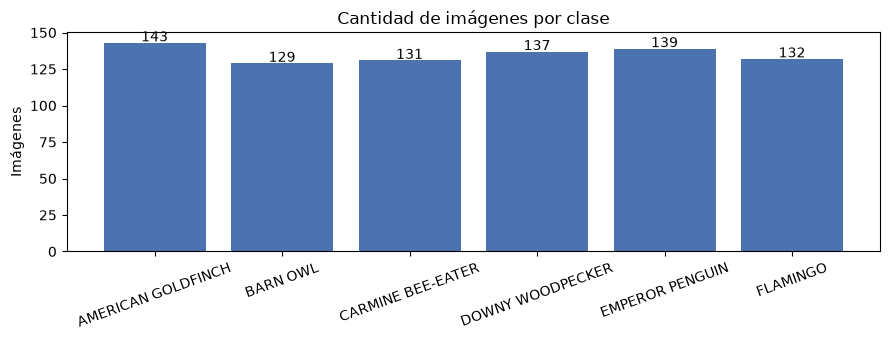

In [3]:
plt.figure(figsize=(9, 3.5))
plt.bar(df_counts["Clase"], df_counts["Imágenes"], color="#4C72B0")
for i, v in enumerate(df_counts["Imágenes"]):
    plt.text(i, v + 1, str(v), ha="center")
plt.title("Cantidad de imágenes por clase")
plt.ylabel("Imágenes")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/imagenes_por_clase.png", dpi=120)
plt.show()

In [4]:
# Dimensiones originales: se revisan TODAS las imágenes
sizes = Counter()
for path, _ in raw_dataset.samples:
    with Image.open(path) as img:
        sizes[(img.width, img.height, img.mode)] += 1

pd.DataFrame(
    [(w, h, mode, n) for (w, h, mode), n in sizes.items()],
    columns=["Ancho (W)", "Alto (H)", "Modo", "Imágenes"],
)

,Ancho (W),Alto (H),Modo,Imágenes
0,224,224,RGB,811


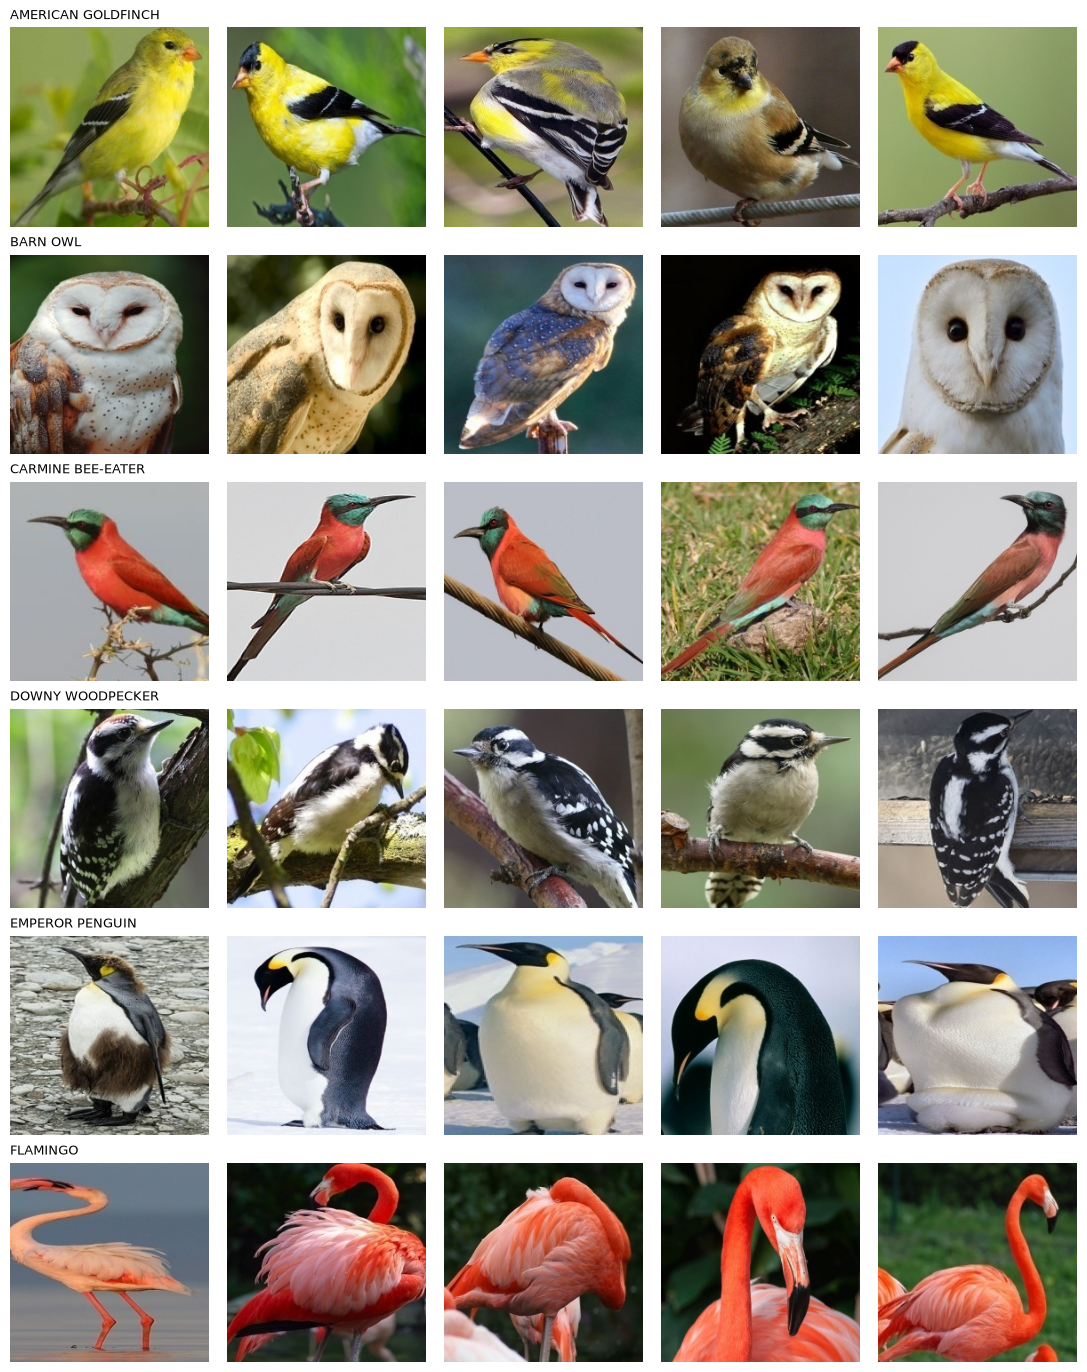

In [5]:
# Ejemplos visuales: 5 imágenes por clase
rng = np.random.default_rng(SEED)
n_cols = 5
fig, axes = plt.subplots(len(raw_dataset.classes), n_cols, figsize=(2.2 * n_cols, 2.3 * len(raw_dataset.classes)))
targets = np.array(raw_dataset.targets)

for c, clase in enumerate(raw_dataset.classes):
    idxs = rng.choice(np.where(targets == c)[0], n_cols, replace=False)
    for k, idx in enumerate(idxs):
        image, _ = raw_dataset[idx]
        axes[c, k].imshow(image)
        axes[c, k].axis("off")
    axes[c, 0].set_title(clase, fontsize=9, loc="left")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ejemplos_dataset.png", dpi=120)
plt.show()

### ¿Por qué este conjunto de datos puede abordarse con una CNN?

- **Es un problema de clasificación de imágenes**: cada imagen RGB tiene una única etiqueta (la especie).
- **La información es espacial**: lo que distingue a las especies son patrones visuales como el color y la textura del plumaje, la forma del pico, el disco facial del búho, el contraste blanco/negro del pingüino o el cuello largo y rosado del flamenco. Una CNN detecta exactamente este tipo de patrones locales con filtros que recorren la imagen, preservando la relación espacial entre píxeles (que un MLP perdería al aplanar la imagen).
- **El ave aparece en distintas posiciones, poses y fondos**: gracias a los **pesos compartidos**, el mismo filtro detecta un patrón (p. ej. un ojo o una textura de plumas) en cualquier parte de la imagen, sin tener que aprender un detector distinto para cada posición.
- **Tamaño manejable**: 811 imágenes de 224×224 RGB, con clases casi balanceadas (129–143 por clase), suficientes para separar entrenamiento, validación y prueba y entrenar una CNN pequeña en CPU/GPU de portátil.

## 2. Preparación de los datos

1. **División**: como el dataset no trae particiones, se hace una división aleatoria con `random_split` (como en el código base del curso), con semilla fija para que sea reproducible:
   **70 % entrenamiento / 15 % validación / 15 % prueba** (567 / 121 / 123 imágenes).
2. **Dimensiones consistentes**: todas las imágenes se redimensionan a **128×128** (las originales son 224×224; 128 reduce ~3× el costo computacional manteniendo detalle suficiente del ave).
3. **Transformaciones** (únicamente las permitidas):
   - `Resize((128, 128))` — cambio de tamaño.
   - `ToTensor()` — convierte la imagen PIL `[H, W, C]` con valores 0–255 a tensor `[C, H, W]` con valores en [0, 1].
   - `Normalize(mean, std)` — estandariza cada canal; **la media y la desviación estándar se calculan solo con el conjunto de entrenamiento** porque los datos de validación y prueba deben permanecer separados del entrenamiento.

In [6]:
IMG_SIZE   = 128
BATCH_SIZE = 32

loader = Loader(root_dir=data_dir, img_size=IMG_SIZE, splits=(0.70, 0.15, 0.15), seed=SEED)
classes = loader.classes

df_split = pd.DataFrame(loader.split_counts())
df_split.loc["Total"] = df_split.sum()
df_split["Total"] = df_split.sum(axis=1)
total = df_split.loc["Total", "Total"]
print("Proporciones:", {k: f"{100 * df_split.loc['Total', k] / total:.1f}%" for k in ["train", "val", "test"]})
print("Transformaciones:", loader.transform)
print(f"Media (train): {np.round(loader.mean, 4)} | Desv. estándar (train): {np.round(loader.std, 4)}")
df_split

Proporciones: {'train': '69.9%', 'val': '14.9%', 'test': '15.2%'}
Transformaciones: Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5161393284797668, 0.5009555816650391, 0.4388771057128906], std=[0.2535039782524109, 0.24594959616661072, 0.2783918082714081])
)
Media (train): [0.5161 0.501  0.4389] | Desv. estándar (train): [0.2535 0.2459 0.2784]


,train,val,test,Total
AMERICAN GOLDFINCH,95,23,25,143
BARN OWL,88,21,20,129
CARMINE BEE-EATER,98,18,15,131
DOWNY WOODPECKER,94,15,28,137
EMPEROR PENGUIN,97,22,20,139
FLAMINGO,95,22,15,132
Total,567,121,123,811


In [7]:
train_loader = loader.train_loader(batch_size=BATCH_SIZE)
val_loader   = loader.val_loader(batch_size=BATCH_SIZE)
test_loader  = loader.test_loader(batch_size=BATCH_SIZE)

images, labels = next(iter(train_loader))
print(f"Tensor de imágenes [B, C, H, W]: {list(images.shape)}  dtype={images.dtype}")
print(f"Tensor de etiquetas [B]:          {list(labels.shape)}  dtype={labels.dtype}")
print(f"Rango de valores tras Normalize: [{images.min():.2f}, {images.max():.2f}]")

Tensor de imágenes [B, C, H, W]: [32, 3, 128, 128]  dtype=torch.float32
Tensor de etiquetas [B]:          [32]  dtype=torch.int64
Rango de valores tras Normalize: [-2.04, 2.03]


**Dimensiones finales de entrada a la red: `[B, C, H, W] = [32, 3, 128, 128]`**

| Componente | Valor | Significado |
|---|---|---|
| **B** | 32 | *Batch size*: número de imágenes procesadas a la vez (el último lote puede ser menor). |
| **C** | 3 | Canales de color (R, G, B). |
| **H** | 128 | Alto de la imagen en píxeles. |
| **W** | 128 | Ancho de la imagen en píxeles. |

Las etiquetas son un tensor `[B]` de enteros (0–5) con el índice de la clase, que es lo que espera `CrossEntropyLoss`.

## 3. Diseño de la arquitectura CNN

Arquitectura propia con **4 bloques convolucionales** (`Conv → ReLU → MaxPool`) y un clasificador de **2 capas completamente conectadas**. Se construye solo con capas básicas de PyTorch (`nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Dropout`, `nn.Linear`).

Tamaño de salida de cada convolución/pooling (fórmula vista en clase):

$$\text{Output} = \left\lfloor \frac{\text{input} - \text{kernel} + 2\cdot\text{padding}}{\text{stride}} \right\rfloor + 1$$

- Conv 3×3, padding 1, stride 1: $(128 - 3 + 2)/1 + 1 = 128$ → conserva el tamaño ("same").
- MaxPool 2×2, stride 2: $(128 - 2)/2 + 1 = 64$ → reduce a la mitad.

| Capa | Configuración | Dimensión de salida |
|---|---|---|
| Entrada | Imagen RGB normalizada | `[B, 3, 128, 128]` |
| Conv1 + ReLU | 32 filtros, kernel 3×3, stride 1, padding 1 (entrada 3 canales) | `[B, 32, 128, 128]` |
| Pool1 | MaxPool 2×2, stride 2 | `[B, 32, 64, 64]` |
| Conv2 + ReLU | 64 filtros, kernel 3×3, stride 1, padding 1 (entrada 32) | `[B, 64, 64, 64]` |
| Pool2 | MaxPool 2×2, stride 2 | `[B, 64, 32, 32]` |
| Conv3 + ReLU | 128 filtros, kernel 3×3, stride 1, padding 1 (entrada 64) | `[B, 128, 32, 32]` |
| Pool3 + Dropout2d | MaxPool 2×2, stride 2; Dropout2d p=0.2 | `[B, 128, 16, 16]` |
| Conv4 + ReLU | 256 filtros, kernel 3×3, stride 1, padding 1 (entrada 128) | `[B, 256, 16, 16]` |
| Pool4 + Dropout2d | MaxPool 2×2, stride 2; Dropout2d p=0.2 | `[B, 256, 8, 8]` |
| Flatten | 256 × 8 × 8 | `[B, 16384]` |
| Linear (FC1) + ReLU + Dropout | 16384 → 128 neuronas; Dropout p=0.5 | `[B, 128]` |
| Salida (FC2) | 128 → 6 neuronas (logits; softmax implícito en `CrossEntropyLoss`) | `[B, 6]` |

**Decisiones de diseño**
- **Kernels 3×3 con padding 1**: filtros pequeños con pocos parámetros; el padding evita perder los bordes y deja que solo el pooling controle la reducción espacial.
- **Número de filtros creciente (32→64→128→256)**: mientras la resolución baja a la mitad en cada bloque, se aumenta la cantidad de mapas de características para representar patrones cada vez más complejos.
- **4 bloques (uno más que el ejemplo de CIFAR‑10)**: las imágenes son de 128×128 (4× más grandes por lado que CIFAR), por lo que se agrega un bloque más para que las últimas capas extraigan características más abstractas (como en "¿Qué ven las CNN?") y para llevar el mapa final a 8×8, lo que limita el tamaño del Flatten.
- **Dropout y Dropout2d** (como en el código base): el dataset es pequeño (567 imágenes de entrenamiento), así que existe el riesgo de que la red memorice las imágenes de entrenamiento en lugar de aprender características generales. Dropout apaga neuronas al azar durante el entrenamiento para que la red no dependa de unas pocas.

In [8]:
model = CNNModel(num_classes=len(classes), in_channels=3, img_size=IMG_SIZE).to(device)
print(model)
print(f"\nParámetros entrenables: {count_parameters(model):,}")

CNNModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout_conv): Dropout2d(p=0.2, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=6, bias=True)
  (relu): ReLU()
)

Parámetros entrenables: 2,486,470


In [9]:
# Verificación de las dimensiones capa por capa con un tensor de ejemplo
def layer_table(model, img_size):
    m = CNNModel(num_classes=len(classes), img_size=img_size).eval()
    m.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()})
    x = torch.zeros(1, 3, img_size, img_size)
    rows = [("Entrada", list(x.shape), 0)]
    nparams = lambda *mods: sum(p.numel() for mod in mods for p in mod.parameters())
    for i in range(1, 5):
        conv = getattr(m, f"conv{i}")
        x = m.relu(conv(x))
        rows.append((f"Conv{i} + ReLU", list(x.shape), nparams(conv)))
        x = m.pool(x)
        rows.append((f"Pool{i}", list(x.shape), 0))
    x = torch.flatten(x, 1); rows.append(("Flatten", list(x.shape), 0))
    x = m.relu(m.fc1(x));     rows.append(("FC1 + ReLU", list(x.shape), nparams(m.fc1)))
    x = m.fc2(x);             rows.append(("FC2 (salida)", list(x.shape), nparams(m.fc2)))
    df = pd.DataFrame(rows, columns=["Capa", "Salida [B, C, H, W]", "Parámetros"])
    df["Salida [B, C, H, W]"] = df["Salida [B, C, H, W]"].astype(str).str.replace("[1,", "[B,", regex=False)
    return df

df_layers = layer_table(model, IMG_SIZE)
print(f"Total: {df_layers['Parámetros'].sum():,} parámetros")
df_layers

Total: 2,486,470 parámetros


,Capa,"Salida [B, C, H, W]",Parámetros
0,Entrada,"[B, 3, 128, 128]",0
1,Conv1 + ReLU,"[B, 32, 128, 128]",896
2,Pool1,"[B, 32, 64, 64]",0
3,Conv2 + ReLU,"[B, 64, 64, 64]",18496
4,Pool2,"[B, 64, 32, 32]",0
5,Conv3 + ReLU,"[B, 128, 32, 32]",73856
6,Pool3,"[B, 128, 16, 16]",0
7,Conv4 + ReLU,"[B, 256, 16, 16]",295168
8,Pool4,"[B, 256, 8, 8]",0
9,Flatten,"[B, 16384]",0


## 4. Entrenamiento

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Función de pérdida | `CrossEntropyLoss` | Clasificación multiclase (6 clases); es la función de pérdida del código base del curso. |
| Optimizador | `Adam` | Optimizador del código base del curso. |
| Learning rate | `1e-3` | Tamaño del paso $\alpha$ en $w := w - \alpha \frac{\partial \mathcal{L}}{\partial w}$; mismo valor del código base. |
| Batch size | `32` | Compromiso entre estabilidad del gradiente y memoria con un dataset pequeño. |
| Número de épocas | `40` | Suficientes para ver en las curvas en qué época el modelo deja de mejorar en validación. |

En cada época se registran **Training Loss, Training Accuracy, Validation Loss y Validation Accuracy**. El conjunto de prueba **no** se usa durante el entrenamiento; se evalúa una sola vez en la sección 6 con el modelo obtenido al final de las 40 épocas.

In [10]:
LEARNING_RATE = 1e-3
NUM_EPOCHS    = 40

set_seed(SEED)
model = CNNModel(num_classes=len(classes), img_size=IMG_SIZE).to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = fit(model, train_loader, val_loader, criterion, optimizer, device, NUM_EPOCHS)

with open(f"{FIG_DIR}/history.json", "w") as f:
    json.dump(history, f, indent=2)

print(f"\nÉpoca con menor Validation Loss: {history['best_epoch']}  -> Val Loss = {history['best_val_loss']:.4f}")

Epoch [1/40] Train Loss: 1.6509 Train Acc: 30.34% Val Loss: 1.0757 Val Acc: 61.16% *


Epoch [2/40] Train Loss: 1.2268 Train Acc: 58.02% Val Loss: 0.7951 Val Acc: 69.42% *


Epoch [3/40] Train Loss: 0.9132 Train Acc: 67.72% Val Loss: 0.5124 Val Acc: 80.17% *


Epoch [4/40] Train Loss: 0.6544 Train Acc: 76.01% Val Loss: 0.4552 Val Acc: 85.95% *


Epoch [5/40] Train Loss: 0.5252 Train Acc: 80.60% Val Loss: 0.4208 Val Acc: 85.12% *


...

Epoch [36/40] Train Loss: 0.0227 Train Acc: 98.94% Val Loss: 0.2433 Val Acc: 95.87%


Epoch [37/40] Train Loss: 0.0513 Train Acc: 98.41% Val Loss: 0.2151 Val Acc: 95.87%


Epoch [38/40] Train Loss: 0.0430 Train Acc: 98.41% Val Loss: 0.2740 Val Acc: 91.74%


Epoch [39/40] Train Loss: 0.0255 Train Acc: 99.12% Val Loss: 0.2194 Val Acc: 93.39%


Epoch [40/40] Train Loss: 0.0581 Train Acc: 98.94% Val Loss: 0.2454 Val Acc: 95.87%

Época con menor Validation Loss: 13  -> Val Loss = 0.1028


In [11]:
df_hist = pd.DataFrame({k: history[k] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]})
df_hist.index = df_hist.index + 1
df_hist.index.name = "Época"
df_hist.columns = ["Training Loss", "Training Acc (%)", "Validation Loss", "Validation Acc (%)"]
df_hist.style.format("{:.4f}").highlight_min(subset=["Validation Loss"], color="#c6efce").highlight_max(subset=["Validation Acc (%)"], color="#c6efce")

,Training Loss,Training Acc (%),Validation Loss,Validation Acc (%)
Época,,,,
1,1.6509,30.3351,1.0757,61.1570
2,1.2268,58.0247,0.7951,69.4215
3,0.9132,67.7249,0.5124,80.1653
4,0.6544,76.0141,0.4552,85.9504
5,0.5252,80.5996,0.4208,85.1240
6,0.4619,84.1270,0.2107,90.9091
7,0.3371,89.0653,0.2694,90.9091
8,0.3397,88.0071,0.2554,93.3884
9,0.2480,90.8289,0.1870,94.2149


## 5. Análisis del entrenamiento

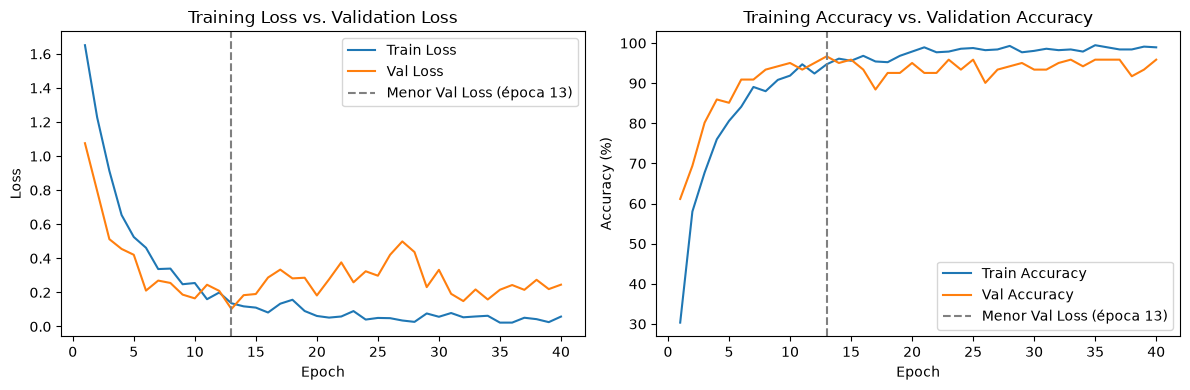

In [12]:
plot_history(history, path=f"{FIG_DIR}/loss_accuracy_plot.png")

In [13]:
best = history["best_epoch"]
best_acc_epoch = int(np.argmax(history["val_acc"])) + 1
summary = pd.DataFrame({
    "Época": [best, best_acc_epoch, NUM_EPOCHS],
    "Train Loss": [history["train_loss"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
    "Val Loss": [history["val_loss"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
    "Train Acc (%)": [history["train_acc"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
    "Val Acc (%)": [history["val_acc"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
}, index=["Menor Val Loss", "Mayor Val Acc", "Última época"])
summary["Brecha Acc (train - val)"] = summary["Train Acc (%)"] - summary["Val Acc (%)"]
summary

,Época,Train Loss,Val Loss,Train Acc (%),Val Acc (%),Brecha Acc (train - val)
Menor Val Loss,13,0.1363,0.1028,94.7090,96.6942,-1.9852
Mayor Val Acc,13,0.1363,0.1028,94.7090,96.6942,-1.9852
Última época,40,0.0581,0.2454,98.9418,95.8678,3.0740


> *Los valores citados corresponden a la ejecución guardada en este notebook. El entrenamiento en GPU (MPS) no es 100 % determinista, por lo que una nueva ejecución puede variar ligeramente.*

**1. ¿En qué época el modelo presenta su mejor comportamiento sobre datos no utilizados durante el entrenamiento?**

En la **época 13**, que tiene la **menor Validation Loss (0,103)** y también la **mayor Validation Accuracy (96,7 %)**. Después de esa época, la pérdida de validación no vuelve a bajar de ese valor.

**2. ¿Qué diferencias se observan entre el comportamiento en entrenamiento y en validación?**

- **Épocas 1–12: ambas curvas mejoran juntas.** La pérdida de entrenamiento y la de validación bajan y la accuracy sube en los dos conjuntos: el modelo está aprendiendo características que sirven también para imágenes que no ha visto. En estas épocas la validación incluso supera al entrenamiento (por ejemplo, 61 % vs. 30 % en la época 1). Esto ocurre porque la accuracy de entrenamiento es el promedio de toda la época mientras los pesos todavía cambian, y además se mide con Dropout activo; la validación se mide al final de la época con el modelo en modo `eval()`.
- **Desde la época 13 las curvas se separan.** La Training Loss sigue bajando hasta valores cercanos a 0 (0,02–0,06) y la Training Accuracy llega a ~99 %. En cambio, la Validation Loss sube y oscila entre 0,15 y 0,50, y la Validation Accuracy se mueve entre 88 % y 96 %. El modelo se sigue ajustando a las imágenes de entrenamiento, pero ya no mejora sobre datos nuevos.
- **Al final (época 40):** 98,9 % en entrenamiento vs. 95,9 % en validación (3,1 puntos de diferencia), y una Validation Loss de 0,245, más del doble que en la época 13.
- **La curva de validación es más irregular** que la de entrenamiento porque el conjunto de validación tiene solo 121 imágenes: cada imagen mal clasificada cambia la accuracy en ~0,8 puntos.

**3. ¿Qué modificaciones se podrían hacer para intentar mejorar el modelo?**

- **Número de épocas:** la Validation Loss deja de mejorar después de la época 13, mientras la Training Loss sigue bajando. Entrenar alrededor de 13 épocas daría el mejor resultado sobre datos no vistos con un tercio del cómputo.
- **Learning rate:** en la regla de actualización $w := w - \alpha \frac{\partial \mathcal{L}}{\partial w}$, un $\alpha$ más pequeño (p. ej. $10^{-4}$) haría pasos más cortos cerca del mínimo y reduciría las oscilaciones de la curva de validación.
- **Batch size:** un batch más grande (p. ej. 64) promedia el gradiente sobre más imágenes, lo que da actualizaciones más estables. Uno más pequeño actualiza los pesos más veces por época.
- **Más capas convolucionales:** apilar dos convoluciones 3×3 antes de cada pooling (como en VGG, pero implementado por nosotros) permite extraer características más abstractas. Agregar un quinto bloque Conv + Pool reduciría el mapa final de 8×8 a 4×4, y FC1 bajaría de 2,10 M a ≈ 0,52 M de parámetros (hoy FC1 concentra el 84 % del modelo).
- **Número y tamaño de los filtros:** probar más filtros por capa o kernels de otro tamaño, y comparar el desempeño en validación.
- **Mayor resolución de entrada:** usar `Resize` a 160 o 224 px (el tamaño original) para conservar más detalle de las formas y del plumaje. Los errores de la sección 6 ocurren entre especies con colores parecidos, y más detalle ayudaría a separarlas.
- **Ajustar el Dropout:** probar otras probabilidades (p. ej. 0,3 o 0,6 en el clasificador) y elegir la que dé menor Validation Loss.

## 6. Evaluación sobre el conjunto de prueba

El conjunto de prueba se usa **solo ahora**, una vez cerradas la arquitectura y el entrenamiento, con el modelo obtenido al final del entrenamiento.

In [14]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
y_true, y_pred, y_prob = predict(model, test_loader, device)

print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}% ({(y_true == y_pred).sum()}/{len(y_true)})")

Test Loss: 0.2796 | Test Accuracy: 95.12% (117/123)


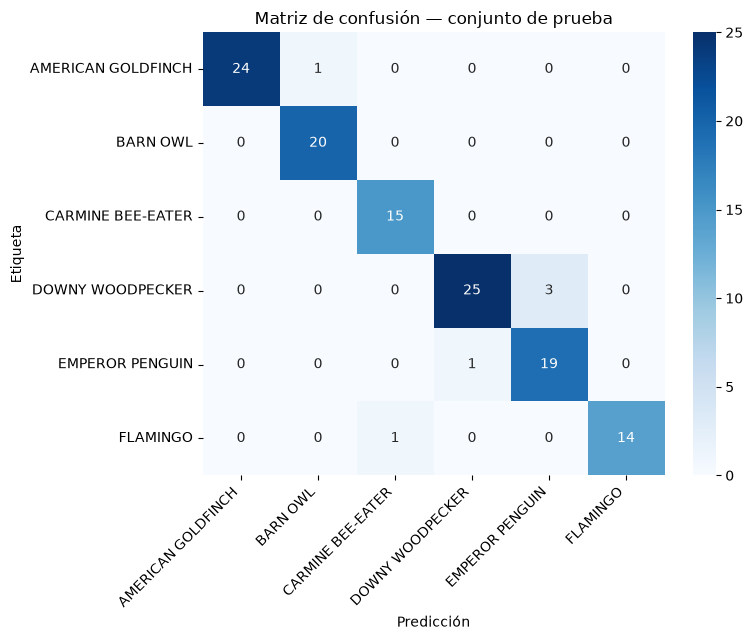

In [15]:
cm = metrics.plot_confusion_matrix(y_true, y_pred, classes, path=f"{FIG_DIR}/matriz_confusion.png",
                                   title="Matriz de confusión — conjunto de prueba")

### Métricas de clasificación

Para un problema multiclase cada métrica se calcula tomando **una clase como positiva y el resto como negativas**, a partir de la matriz de confusión:

- **Accuracy** $= \frac{TP+TN}{TP+TN+FP+FN}$ — proporción total de aciertos.
- **Precision** $= \frac{TP}{TP+FP}$ — de las veces que el modelo predijo la clase, cuántas acertó.
- **Recall / Sensibilidad** $= \frac{TP}{TP+FN}$ — de las imágenes de la clase, cuántas detectó.
- **Especificidad** $= \frac{TN}{TN+FP}$ — qué tan bien reconoce que una imagen *no* es de la clase.
- **Tasa de falsos positivos** $= \frac{FP}{FP+TN}$ y **tasa de falsos negativos** $= \frac{FN}{FN+TP}$.
- **F1‑Score** $= 2\cdot\frac{Precision \cdot Recall}{Precision + Recall}$.
- **AUC‑ROC** — área bajo la curva ROC (sensibilidad vs. 1 − especificidad al variar el umbral), calculada con las probabilidades softmax.

In [16]:
metrics.summary_metrics(y_true, y_pred, y_prob, classes).to_frame("Valor")

,Valor
Accuracy,0.9512
Precision (promedio),0.9525
Recall (promedio),0.9560
Especificidad (promedio),0.9902
F1-Score (promedio),0.9532
AUC-ROC (promedio),0.9958


In [17]:
df_per_class = metrics.per_class_metrics(cm, classes)
df_per_class

,TP,FP,FN,TN,Precision,Recall (Sensibilidad),Especificidad,Tasa FP,Tasa FN,F1-Score
Clase,,,,,,,,,,
AMERICAN GOLDFINCH,24,0,1,98,1.0000,0.9600,1.0000,0.0000,0.0400,0.9796
BARN OWL,20,1,0,102,0.9524,1.0000,0.9903,0.0097,0.0000,0.9756
CARMINE BEE-EATER,15,1,0,107,0.9375,1.0000,0.9907,0.0093,0.0000,0.9677
DOWNY WOODPECKER,25,1,3,94,0.9615,0.8929,0.9895,0.0105,0.1071,0.9259
EMPEROR PENGUIN,19,3,1,100,0.8636,0.9500,0.9709,0.0291,0.0500,0.9048
FLAMINGO,14,0,1,108,1.0000,0.9333,1.0000,0.0000,0.0667,0.9655


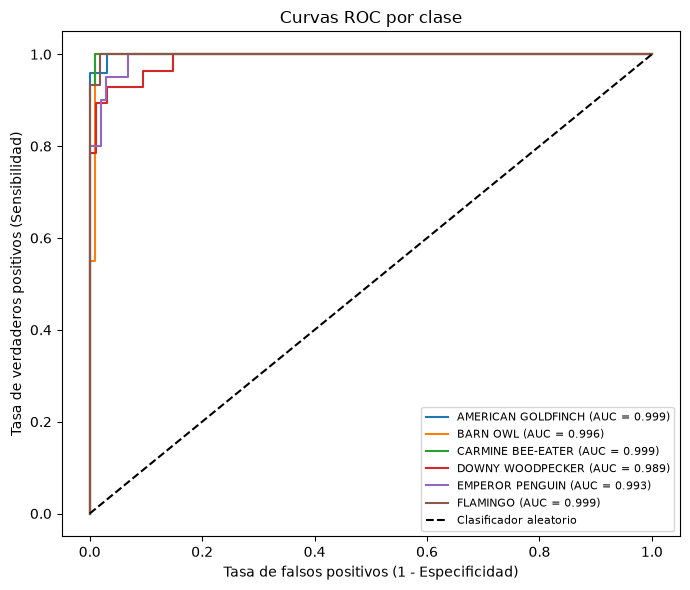

In [18]:
metrics.plot_roc_curves(y_true, y_prob, classes, path=f"{FIG_DIR}/curvas_roc.png")

### Predicciones correctas e incorrectas

Correctas: 117 | Incorrectas: 6


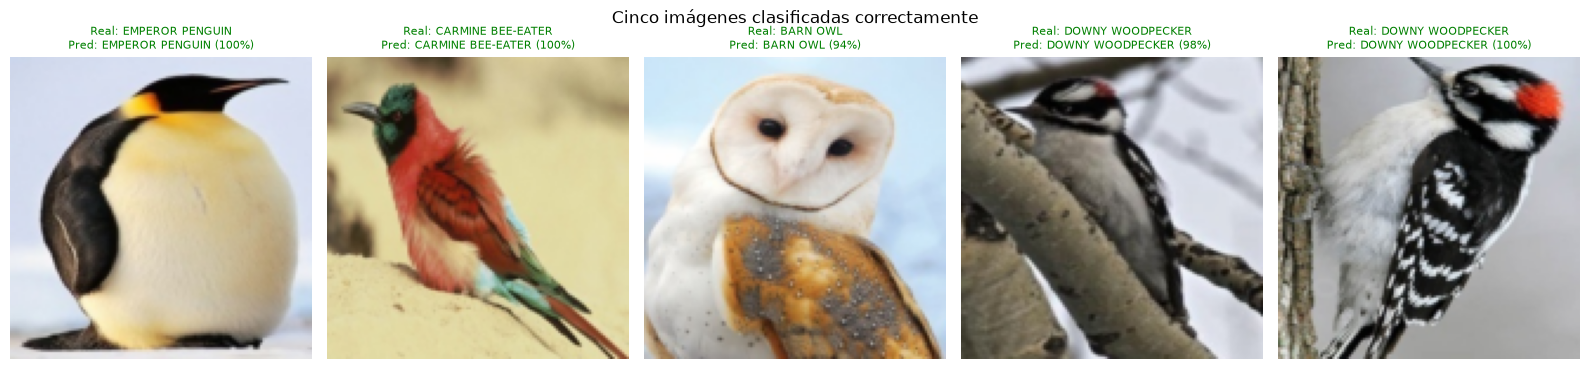

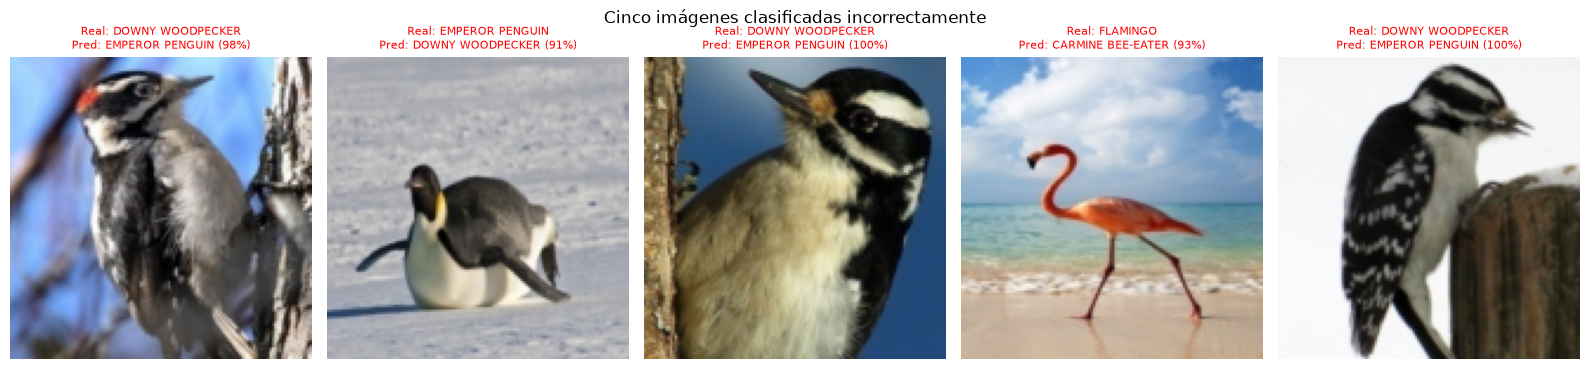

In [19]:
correct_pos   = np.where(y_true == y_pred)[0]
incorrect_pos = np.where(y_true != y_pred)[0]
print(f"Correctas: {len(correct_pos)} | Incorrectas: {len(incorrect_pos)}")

rng = np.random.default_rng(SEED)
sel_correct   = rng.choice(correct_pos, min(5, len(correct_pos)), replace=False)
sel_incorrect = rng.choice(incorrect_pos, min(5, len(incorrect_pos)), replace=False)

metrics.show_predictions(loader.test_dataset, sel_correct, y_true, y_pred, y_prob, classes,
                         loader.mean, loader.std, "Cinco imágenes clasificadas correctamente",
                         path=f"{FIG_DIR}/predicciones_correctas.png")
metrics.show_predictions(loader.test_dataset, sel_incorrect, y_true, y_pred, y_prob, classes,
                         loader.mean, loader.std, "Cinco imágenes clasificadas incorrectamente",
                         path=f"{FIG_DIR}/predicciones_incorrectas.png")

In [20]:
print("Pares de clases más confundidos (real -> predicha):")
metrics.top_confusions(cm, classes, k=6)

Pares de clases más confundidos (real -> predicha):


,Clase real,Clase predicha,Errores
0,DOWNY WOODPECKER,EMPEROR PENGUIN,3
1,AMERICAN GOLDFINCH,BARN OWL,1
2,EMPEROR PENGUIN,DOWNY WOODPECKER,1
3,FLAMINGO,CARMINE BEE-EATER,1


### Resultados en prueba

- **Accuracy: 95,1 %** (117 de 123 imágenes), con el modelo de la época 40. Es similar a la Validation Accuracy de esa misma época (95,9 %).
- **Precision, Recall y F1‑Score promedio ≈ 0,95**, **Especificidad promedio 0,99** y **AUC‑ROC promedio 0,996**. Un AUC cercano a 1 indica que, para cada clase, el modelo asigna probabilidades más altas a las imágenes de esa clase que a las del resto.
- **AMERICAN GOLDFINCH, BARN OWL, CARMINE BEE‑EATER y FLAMINGO** tienen F1 entre 0,97 y 0,98.
- Las dos clases más débiles son **DOWNY WOODPECKER** (recall 0,89: 3 de sus 28 imágenes no se reconocen) y **EMPEROR PENGUIN** (precision 0,86: 3 imágenes de otras clases se predijeron como pingüino, la mayor tasa de falsos positivos, 0,029).

### ¿Existen clases que el modelo tienda a confundir entre sí?

Sí. Hay 6 errores en total y la mayoría se concentra en un par de clases:

1. **DOWNY WOODPECKER ↔ EMPEROR PENGUIN (4 errores: 3 pájaros carpinteros predichos como pingüino y 1 pingüino predicho como carpintero).** Es la confusión principal. Ambas especies tienen **plumaje blanco y negro con mucho contraste**. En las imágenes mal clasificadas, el carpintero aparece en primer plano o sobre un fondo claro, y el pingüino aparece acostado sobre la nieve, lo que cambia su silueta habitual. Además, el modelo se equivoca con mucha confianza (91–100 %).
2. **FLAMINGO → CARMINE BEE‑EATER (1 error, 93 %).** Las dos especies tienen tonos **rojo‑anaranjados/rosados**. Este flamenco es más anaranjado que la mayoría.
3. **AMERICAN GOLDFINCH → BARN OWL (1 error).**

**Conclusión:** las confusiones ocurren entre especies con **colores y contrastes parecidos**, más que con formas parecidas. Esto indica que el modelo se apoya mucho en el color. Que se equivoque con tanta confianza es coherente con lo visto en la sección 5: al final del entrenamiento el modelo está muy ajustado a las imágenes de entrenamiento.

## 7. Preguntas de análisis

Para apoyar la Pregunta 1 se visualizan algunos **mapas de características** de cada bloque convolucional para una imagen de prueba (como en las diapositivas "¿Qué ven las CNN?").

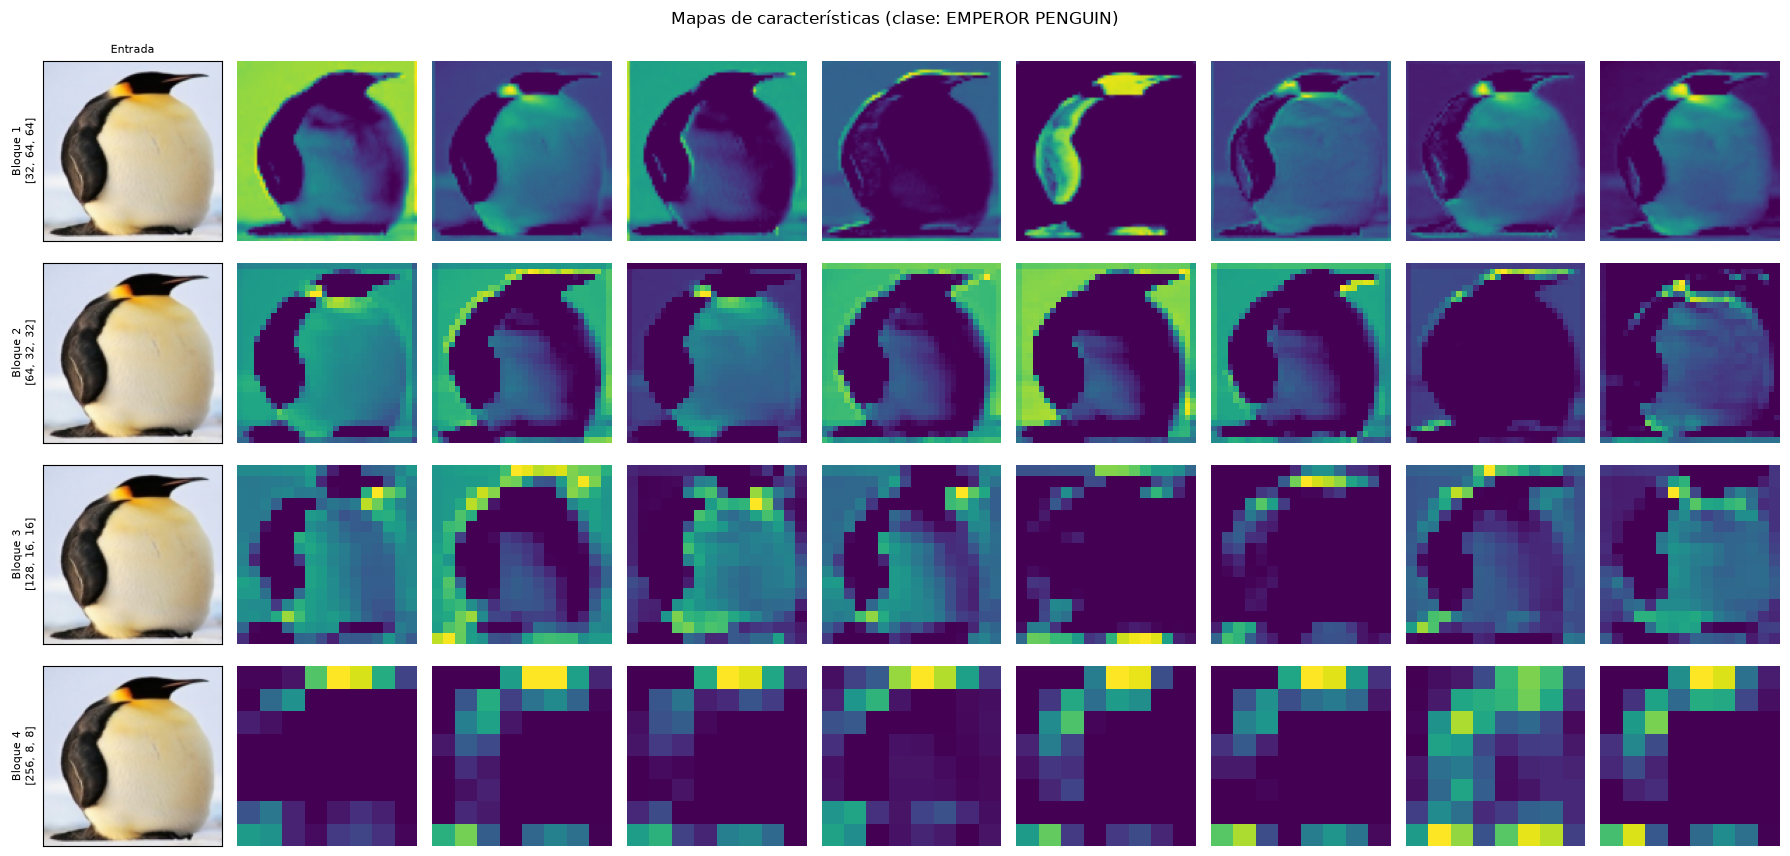

In [21]:
model.eval()
image, label = loader.test_dataset[int(sel_correct[0])]
with torch.no_grad():
    maps = [m[0].cpu() for m in model.features(image.unsqueeze(0).to(device))]

n_show = 8
fig, axes = plt.subplots(len(maps), n_show + 1, figsize=(2 * (n_show + 1), 2.2 * len(maps)))
for b, fmap in enumerate(maps):
    axes[b, 0].imshow(metrics.denormalize(image, loader.mean, loader.std))
    axes[b, 0].set_title("Entrada" if b == 0 else "", fontsize=8)
    axes[b, 0].set_ylabel(f"Bloque {b + 1}\n{list(fmap.shape)}", fontsize=8)
    axes[b, 0].set_xticks([]); axes[b, 0].set_yticks([])
    top = fmap.mean(dim=(1, 2)).argsort(descending=True)[:n_show]     # canales más activados
    for k, ch in enumerate(top):
        axes[b, k + 1].imshow(fmap[ch], cmap="viridis")
        axes[b, k + 1].axis("off")
plt.suptitle(f"Mapas de características (clase: {classes[label]})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/mapas_caracteristicas.png", dpi=120)
plt.show()

### Pregunta 1: ¿Qué características se espera que aprendan las capas convolucionales?

Los mapas de características de arriba (un pingüino emperador del conjunto de prueba) muestran que a medida que se avanza en profundidad, las características pasan de simples a abstractas.

- **Primeras capas convolucionales (Bloque 1, 32 filtros, 64×64):** detectan **bordes, contornos y cambios de color**, como lo harían filtros tipo Sobel, pero aprendidos durante el entrenamiento. Los mapas todavía se parecen a la imagen: se ve la silueta del pingüino, el borde entre el lomo negro y el pecho blanco, el contorno del pico y la mancha amarilla del cuello resaltada por separado.
- **Capas intermedias (Bloques 2 y 3, 64 y 128 filtros, 32×32 y 16×16):** combinan esos bordes en **formas y texturas**: regiones completas (el lomo oscuro, el pecho, la cabeza) y contornos del cuerpo. Los mapas son más gruesos y resaltan **partes** del ave en lugar de bordes finos.
- **Capas más profundas (Bloque 4, 256 filtros, 8×8):** características **abstractas y específicas de la tarea**. Los mapas ya no se parecen a la imagen: se activan pocas posiciones, concentradas en la zona de la cabeza y el cuello (la parte más característica del pingüino emperador) y en la base del cuerpo. Estas activaciones son las que recibe el clasificador (FC1 → FC2) para decidir la especie.

### Pregunta 2: ¿Cuál es el propósito del pooling en esta arquitectura?

Cada bloque termina con un **MaxPool 2×2 con stride 2**, que se aplica 4 veces: **128 → 64 → 32 → 16 → 8**. Su propósito en esta red es:

1. **Reducir el tamaño de los mapas de características:** cada pooling reduce el alto y el ancho a la mitad, es decir, 4 veces menos valores por mapa.
2. **Disminuir el costo computacional:** cada convolución siguiente opera sobre mapas más pequeños, aunque tenga más filtros (32 → 64 → 128 → 256).
3. **Conservar las activaciones más importantes:** el max pooling se queda con el valor máximo de cada ventana 2×2, es decir, con la respuesta más fuerte de cada filtro en esa región, y descarta el resto. Así resume cada región del mapa sin perder la información relevante.
4. **Controlar el número de parámetros del clasificador:** gracias al pooling, el Flatten produce 256×8×8 = **16 384** valores y FC1 tiene 2,1 M de parámetros. Sin pooling, el Flatten tendría 256×128×128 = 4 194 304 valores y **FC1 tendría ≈ 537 millones de parámetros**, imposible de entrenar con 567 imágenes.

In [22]:
# Pregunta 3: CNN vs. red completamente conectada sobre todos los píxeles
input_size = IMG_SIZE * IMG_SIZE * 3
mlp = MLPModel(input_size, len(classes))      # MLP del código base: entrada -> 512 -> 512 -> 6

cnn_params = count_parameters(model)
mlp_params = count_parameters(mlp)
conv_params = sum(p.numel() for n, p in model.named_parameters() if n.startswith("conv"))
mlp_first   = sum(p.numel() for p in mlp.fc1.parameters())

orig_input = 224 * 224 * 3
comparison = pd.DataFrame({
    "Modelo": [
        "CNN propia (completa)",
        "  - solo bloques convolucionales",
        "MLP 128×128×3 → 512 → 512 → 6",
        "  - solo la primera capa densa",
        "MLP 224×224×3 (tamaño original) → 512 → 512 → 6",
    ],
    "Parámetros": [
        cnn_params, conv_params, mlp_params, mlp_first,
        count_parameters(MLPModel(orig_input, len(classes))),
    ],
})
comparison["Veces la CNN"] = comparison["Parámetros"] / cnn_params
print(f"Entradas del MLP: {IMG_SIZE}×{IMG_SIZE}×3 = {input_size:,} píxeles")
comparison

Entradas del MLP: 128×128×3 = 49,152 píxeles


,Modelo,Parámetros,Veces la CNN
0,CNN propia (completa),2486470,1.0000
1,- solo bloques convolucionales,388416,0.1562
2,MLP 128×128×3 → 512 → 512 → 6,25432070,10.2282
3,- solo la primera capa densa,25166336,10.1213
4,MLP 224×224×3 (tamaño original) → 512 → 512 → 6,77336582,31.1030


### Pregunta 3: ¿Qué ocurriría con el número de parámetros si las capas convolucionales se reemplazaran por capas completamente conectadas que procesen todos los píxeles?

**El número de parámetros aumentaría enormemente.** En una capa densa, cada neurona se conecta a **todos** los píxeles, así que sus pesos crecen proporcionalmente al tamaño de la imagen (el mismo cálculo de la diapositiva "¿Por qué no usar una red neuronal tradicional?"):

- Entrada aplanada: 128 × 128 × 3 = **49 152** valores.
- Solo la primera capa densa del MLP del curso (512 neuronas): 49 152 × 512 + 512 = **25 166 336 parámetros**, es decir, **≈ 10 veces la CNN completa** (2 486 470).
- MLP completo (49 152 → 512 → 512 → 6): **25,4 M** de parámetros (10,2×).
- Con las imágenes en su tamaño original (224×224×3 = 150 528 entradas): **77,3 M** de parámetros (31×).

En cambio, **todos los bloques convolucionales de la CNN suman solo 388 416 parámetros (15,6 % del modelo)**, gracias a la **conectividad local** y a los **pesos compartidos**: Conv1 tiene 3×3×3×32 + 32 = 896 parámetros, sin importar si la imagen es de 128 o de 224 píxeles, porque el mismo filtro recorre toda la imagen. El efecto se ve incluso dentro de nuestra CNN: la única capa densa grande (FC1) concentra el 84 % de los parámetros.

Además del número de parámetros, al aplanar la imagen **se pierde la relación espacial entre los píxeles**: la red no podría detectar directamente bordes, texturas y formas, y tendría que aprender un detector distinto para el mismo patrón (por ejemplo, un ojo) en cada posición de la imagen. Una CNN lo aprende una sola vez y lo aplica en toda la imagen.

## Conclusiones

- Se diseñó y entrenó una CNN propia de 4 bloques convolucionales (2,49 M de parámetros), usando solo capas básicas de PyTorch. Alcanza **95,1 % de accuracy, F1 promedio ≈ 0,95 y AUC‑ROC ≈ 0,996** en el conjunto de prueba, que se usó una sola vez al final.
- Las curvas muestran que el mejor comportamiento sobre datos no vistos se alcanza en la **época 13**. Después, el modelo se sigue ajustando a las imágenes de entrenamiento sin mejorar en validación, así que entrenar menos épocas o ajustar el learning rate son los primeros cambios a probar.
- Los errores se concentran en especies con **colores y contrastes parecidos** (pájaro carpintero ↔ pingüino emperador, flamenco → abejaruco carmín), lo que indica que el modelo depende mucho del color.
- La comparación con un MLP confirma la ventaja de las convoluciones: con **10 veces menos parámetros** que una sola capa densa sobre los píxeles, la CNN aprovecha la estructura espacial de la imagen mediante filtros locales y pesos compartidos.